In [164]:
from grokkingexperiments.config import print_config, load_config
from grokkingexperiments.model import GrokkingModel
from grokkingexperiments.groups.zn import Zn

import torch
import numpy as np
import matplotlib.pyplot as plt

import scienceplots
plt.style.use(["science", "ieee", "notebook"])
# plt.style.use(["science", "notebook"])


device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} to train")

Using cpu to train


### Setup

Load config

In [165]:
config = load_config()
print_config(config)

Config
  model
    | actv_func            relu
    | embed_dim            128
    | hidden_dim           256
  train
    | epochs               250000
  group
    | name                 Zn
    | n                    113
    | split                0.4
  settings
    | seed                 1337
    | print_progress       True
    | progress_interval    100
    | model_dir            data/models/
    | model_filename       custom_model.pt


Train if model dumps don't exist

In [166]:

# # Save the initalised model
# config.settings.model_filename = "Z_113_initial.pt"
# model = GrokkingModel(config).to(device)
# model.save()

# # Using same random seed, init a new model to train
# config.settings.model_filename = "Z_113_trained.pt"
# model = GrokkingModel(config).to(device)

# zn = Zn(config)

# # Generate the data
# x_train, y_train, x_test, y_test = zn.generate_train_test_data()

# # Move to GPU if available
# x_train = x_train.to(device)
# y_train = y_train.to(device)
# x_test = x_test.to(device)
# y_test = y_test.to(device)

# # Train the model
# model.fit(x_train, y_train, x_test, y_test)
# model.save();

Load models

In [167]:
initial_model = GrokkingModel(config).to(device)
initial_model.load_model("../../../../data/models/Z_113_initial.pt")

trained_model = GrokkingModel(config).to(device)
trained_model.load_model("../../../../data/models/Z_113_trained.pt")

GrokkingModel(
  (relu): ReLU()
)

### What does our model look like

Let $G$ be a finite group of order $|G|$. 
Let $d$ be our embedding dimension, and $h$ be the hidden dimension.
Let $a,b \in G$, we can define our model as:
$$\mathbf{z}(a,b) = W_U\text{ReLU}\left(W_H \begin{bmatrix}E_L \mathbf{e}_a \\ E_R \mathbf{e}_b \end{bmatrix}\right)$$
where:
- $E_L, E_R \in \mathbb{R}^{d \times |G|}$
- $\mathbf{e}_a, \mathbf{e}_b \in \mathbb{R}^{|G|}$, one hot vector where $\mathbf{e}_a$ is the  $a$-th standard basis, similar for $\mathbf{e}_b$
- $W_H \in \mathbb{R}^{h \times 2d}$
- $W_U \in \mathbb{R}^{|G| \times h}$

In [168]:
trained_weights = trained_model.state_dict()

n = config.group.n
E_L = trained_weights["E_L"]
E_R = trained_weights["E_R"]
W_H = trained_weights["W_H"]
W_U = trained_weights["W_U"]


print(f"|G|       = {n}")
print(f"d         = {config.model.embed_dim}")
print(f"h         = {config.model.hidden_dim}")
print(f"{E_L.shape = }")
print(f"{E_R.shape = }")
print(f"{W_H.shape = }")
print(f"{W_U.shape = }")

|G|       = 113
d         = 128
h         = 256
E_L.shape = torch.Size([128, 113])
E_R.shape = torch.Size([128, 113])
W_H.shape = torch.Size([256, 256])
W_U.shape = torch.Size([113, 256])


Did our model Grok?

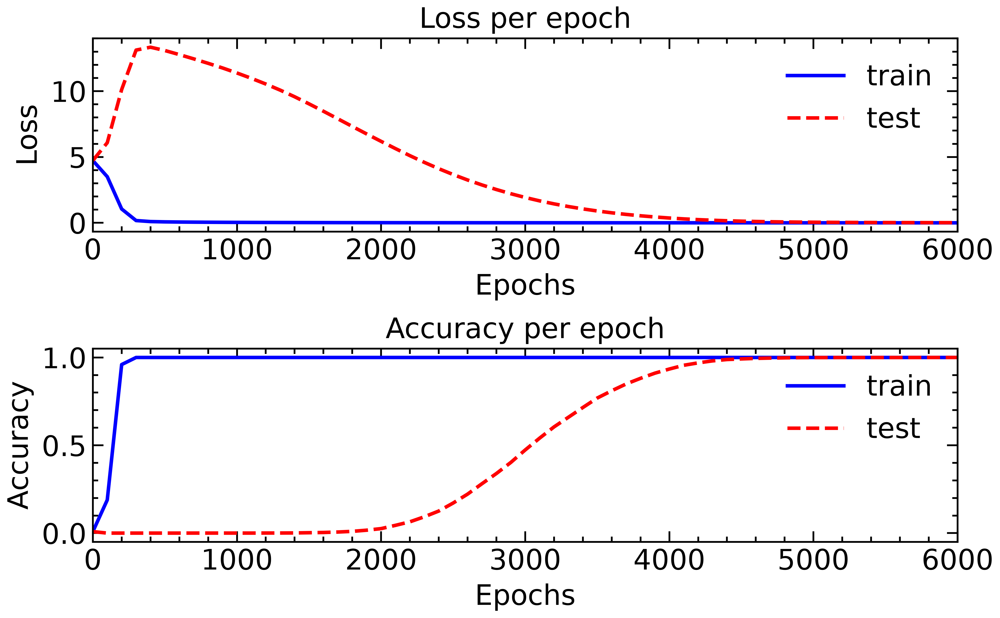

In [169]:
trained_model.plot_metrics(end_epoch = 6_000)

### How strongly does our model believe that $a+b \bmod n \equiv 0$ for each input pair $(a,b)$?


In other words, let’s inspect the model’s $0$ th logit as we vary $a$ and $b$.

In PyTorch, we can pass all possible input pairs $[a,b]$ to the model at once. This creates an input matrix $X \in \mathbb{R}^{|G|^2 \times 2}$ where each row is one input pair $(a,b)$. 

The model then produces a logit matrix $M \in \mathbb{R}^{|G|^2 \times |G|}$ where each row contains the $|G|$ logits for the corresponding input pair.

We select the 0 logit by selecting the $0th$ column of $M$:
$$s_0 = M[:, 0] \in \mathbb{R}^{{|G|}^2}$$
and reshaping to a $|G| \times |G|$ matrix who's $(a,b)$ entry is the model’s score for output $0$ on input pair $(a,b)$.

You can view the implementation below, or see `plot_logit()` in `model.py`

In [170]:
# # Create a matrix M of shape (|G|^2, 2) of all input pairs
# X = torch.zeros((n**2, 2), dtype=torch.int64)
# for i in range(n):
#     for j in range(n):
#         X[(i *n) + j] = torch.tensor([i,j])


# # Get logits for all a,b
# M = trained_model(X)

# # Slice column to obtain 0th logit scores
# s_0 = M[:, 0]

# # Reshape
# L_0 = s_0.reshape(n,n)

# print(f"{X.shape = }")
# print(f"{M.shape = }")
# print(f"{s_0.shape = }")
# print(f"{L_0.shape = }")


# plt.imshow(L_0.detach(), cmap="hot", origin="lower")
# plt.title("Model's Score for Answer 0")
# plt.xlabel("Input a")
# plt.ylabel("Input b")
# plt.xticks(range(0, n, 10))
# plt.yticks(range(0, n, 10))
# plt.colorbar(label="Model Score (Logit)")
# plt.show()

Lets first inspect our untrained model. We should expect random noise

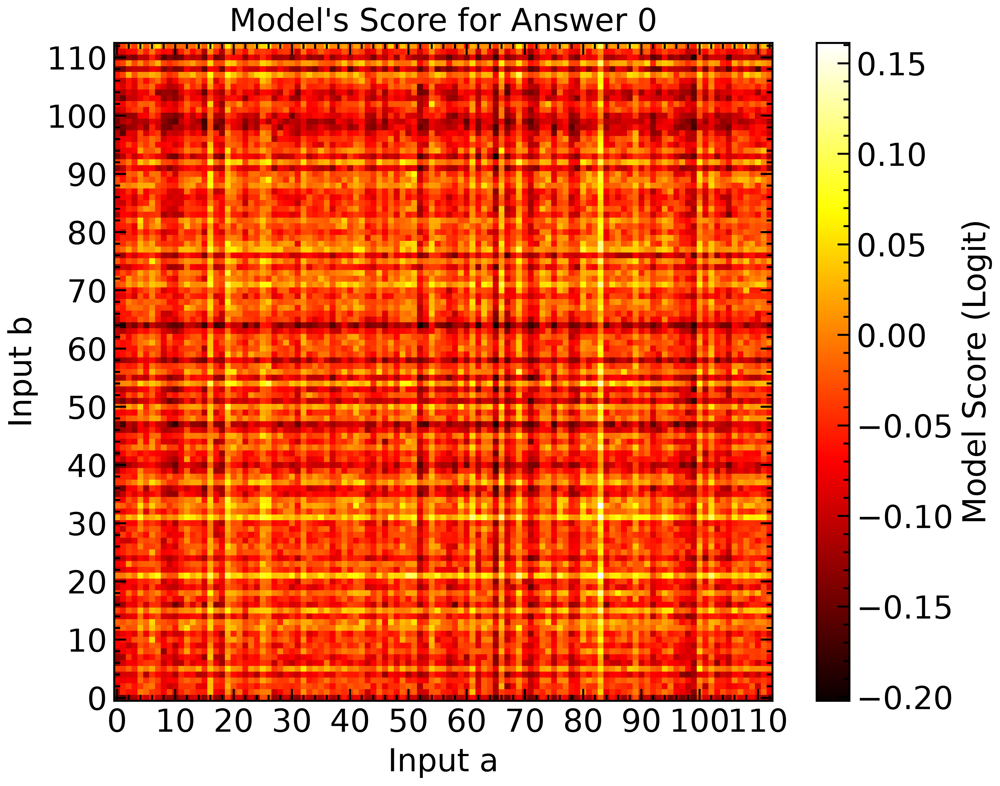

In [171]:
initial_model.plot_logit(0)

Plotting our trained model, we see our model has correctly learned to assign high scores to those $a,b$ that satisfy $a + b \bmod n$

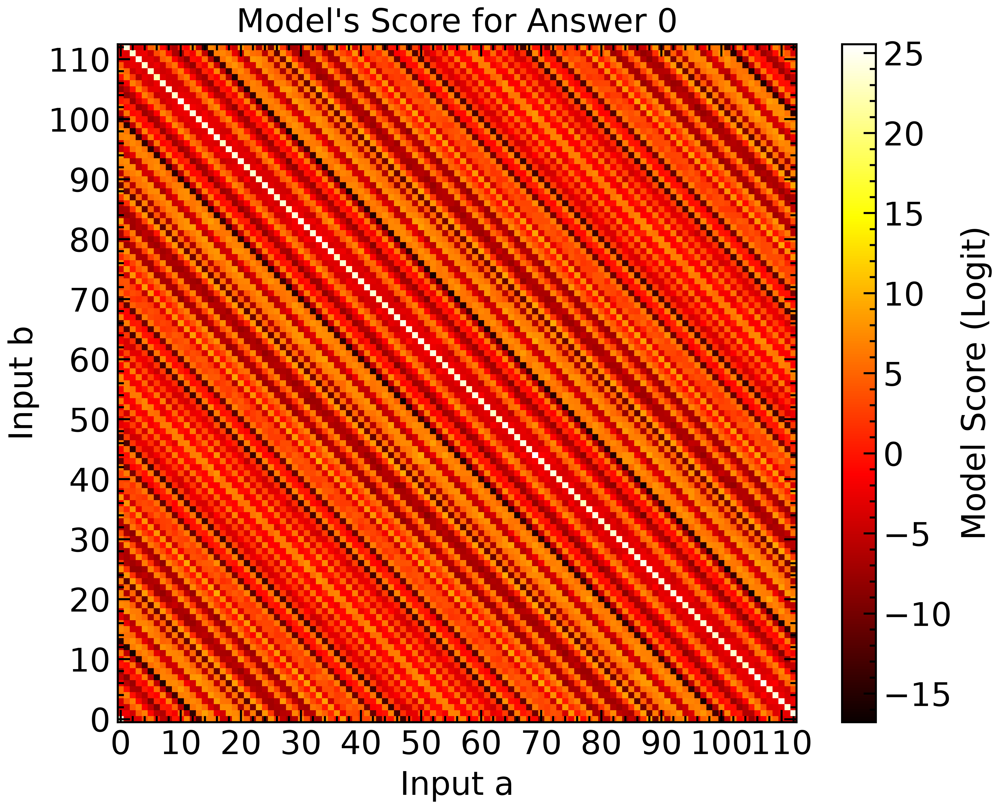

In [172]:
trained_model.plot_logit(0)

### What do our hidden neurons look like?

Lets recall, our hidden preactivation vector is calculated:

$$\mathbf{z}(a,b) =  W_H \begin{bmatrix} E_L \mathbf{e}_a \\ E_R \mathbf{e}_b \end{bmatrix} =  W_H \begin{bmatrix} \mathbf{u}_a \\ \mathbf{v}_b \end{bmatrix} = \begin{bmatrix} \text{---} \mathbf{w}_0^T \text{---} \\ \text{---} \mathbf{w}_1^T \text{---} \\  \vdots \\ \text{---} \mathbf{w}_{h-1}^T  \text{---} \end{bmatrix}\begin{bmatrix} \mathbf{u}_a \\ \mathbf{v}_b \end{bmatrix}$$

since $W_H \in \mathbb{R}^{h \times 2d}$, we can partition it into two blocks of $d$ columns:
$$W_H = \begin{bmatrix} W_H^{(L)} & W_H^{(R)}\end{bmatrix}$$
where: 
$$W_H^{(L)} = W_H[:, :d]$$
and 
$$W_H^{(R)} = W_H[:, d:]$$

hence:
$$\mathbf{z}(a,b) = W_H \begin{bmatrix} \mathbf{u}_a \\ \mathbf{v}_b \end{bmatrix} =  \begin{bmatrix} W_H^{(L)} & W_H^{(R)}\end{bmatrix}\begin{bmatrix} \mathbf{u}_a \\ \mathbf{v}_b \end{bmatrix}  = 
W_H^{(L)} \mathbf{u}_a + W_H^{(R)}\mathbf{v}_b$$ 

such that neuron $i$ preactivation is:

$$ \mathbf{z}(a,b) = 
z_i(a,b) =
(\mathbf{w}_i^{(L)})^T \mathbf{u}_a
+
(\mathbf{w}_i^{(R)})^T \mathbf{v}_b
$$

In [173]:
# # Nueron to visualise
# i = 1

# # Get embedding dimension
# d = E_L.shape[0]

# # Compute hidden neuron left/right contributions for each group element
# W_H_L = W_H[:, :d] @ E_L
# W_H_R = W_H[:, d:] @ E_R 

# print(f"{W_H_L.shape  = }")
# print(f"{W_H_R.shape = }")
# print(f"{W_H_L[i, :, None].shape = }")
# print(f"{W_H_R[i, None, :].shape = }")

# # Two methods to get activations for all a,b, both are equivalent:
# # 1) Loop over all pairs 
# Z_i = torch.zeros((n, n))
# for a in range(n):
#     for b in range(n):
#         Z_i[a, b] = W_H_L[i, a] + W_H_R[i, b]

# plt.imshow(Z_i)
# plt.show()


# # 2) Broadcast
# Z_i = W_H_L[i, :, None] + W_H_R[i, None, :]
# plt.imshow(Z_i)
# plt.show()

We can plot all neurons preactivations across all input pairs (a,b)

In [174]:
# initial_model.plot_all_hidden_neurons()
# trained_model.plot_all_hidden_neurons()

Lets visualize the preactivations of hidden neurons $0, 13, 37$

Untrained model










In [175]:
initial_model.plot_hidden_neuron_values(0)
initial_model.plot_hidden_neuron_values(13)
initial_model.plot_hidden_neuron_values(37)










In [176]:
trained_model.plot_hidden_neuron_values(0)
trained_model.plot_hidden_neuron_values(13)
trained_model.plot_hidden_neuron_values(37)

Our model has learned something periodic... How do we inspect this further? Lets take a closer look at neuron 0

The Discrete Fourier Transform allows us to express any finite sequence as a sum of frequencies. Consider the wave formed by adding the two waves below.

For a sequence of $N$ discrete sample there are $N$ distinct possible frequencies present. We can write our wave as:

$$f(x) = \frac{1}{N} \sum_{k=0}^{N-1} c_k e^{\frac{2\pi kx}{N}}$$

The Discrete Fourier Transform allows us to recover these coeffecients:
$$c_k = \sum_{x = 0}^{N-1} f(x)e^{- \frac{2\pi k x}{N}}$$

we can collect them into a vector:
$$\mathbf{c} = [c_0, c_1, \dots, c_{112}] \in \mathbb{C}^{N}$$
where

Since $f(x)$ is real valued, the coeefs have conjugate symmetry:
$$c_{N - k} = \overline{c_{k}}$$

We calculuate the magnitude $|c_k|$ to find how much frequency $k$ is present in the signal

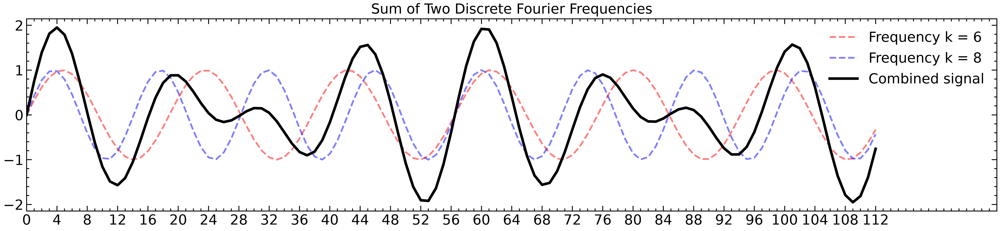

In [177]:
# https://csundergrad.science.uoit.ca/courses/cv-notes/notebooks/05-frequency-analysis.html

x = np.arange(113)

k_1 = 6
k_2 = 8


plt.figure(figsize=(20,4))
y_1 = np.sin(2 * np.pi * k_1 * x / 113)
y_2 = np.sin(2 * np.pi * k_2 * x / 113)
combined = y_1 + y_2

plt.plot(x, y_1, c="r", alpha=0.5, ls="--", label=f"Frequency k = {k_1}")
plt.plot(x, y_2, c="b", alpha=0.5, ls="--", label=f"Frequency k = {k_2}")
plt.plot(x, combined, c="black", lw=3, label="Combined signal")

plt.title("Sum of Two Discrete Fourier Frequencies")
plt.xlim(0, 128)  
plt.xticks(np.arange(0, 113, 4))
plt.legend()
plt.show()

(57,)
top_k[:4] = array([ 8,  6, 21, 29])


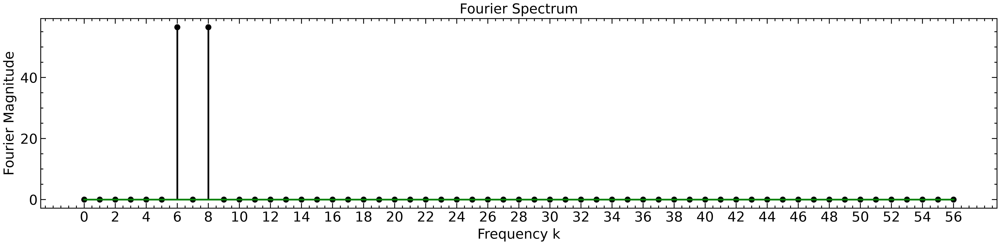

In [178]:
coeffs = np.fft.rfft(combined)
magnitudes = np.abs(coeffs)
top_k = np.argsort(magnitudes)[::-1]

print(f"{coeffs.shape}")
print(f"{top_k[:4] = }")


plt.figure(figsize=(20,4))
plt.stem(np.arange(57), np.abs(coeffs))
plt.xlabel("Frequency k")
plt.ylabel("Fourier Magnitude")
plt.title("Fourier Spectrum")
plt.xticks(np.arange(0, 57, 2))
plt.show()

As we mentioned, DFT allows us to express any finite sequence as a sum of frequncies. Lets take a look at what frequencies a random sequence contains. 

(57,)
top_k[:4] = array([38, 43, 42, 19])


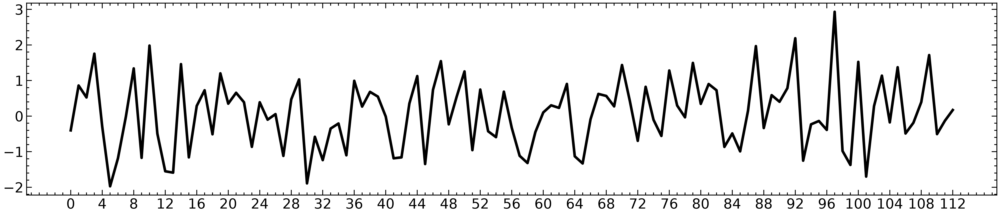

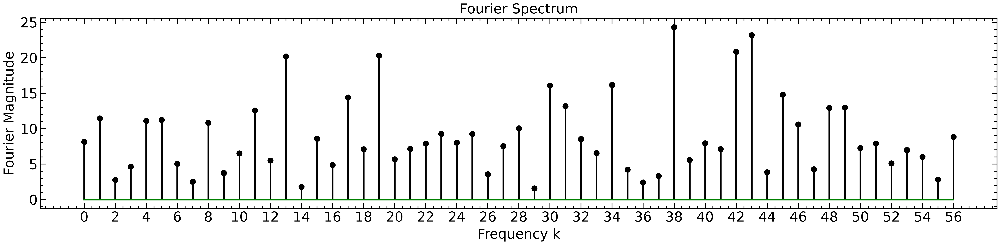

In [179]:
x = np.arange(113)
y = np.random.randn(113)

plt.figure(figsize=(20,4))
plt.plot(x, y, c="black", lw=3)
plt.xticks(np.arange(0, 113, 4))

coeffs = np.fft.rfft(y)
magnitudes = np.abs(coeffs)
top_k = np.argsort(magnitudes)[::-1]

print(f"{coeffs.shape}")
print(f"{top_k[:4] = }")


plt.figure(figsize=(20,4))
plt.stem(np.arange(57), np.abs(coeffs))
plt.xlabel("Frequency k")
plt.ylabel("Fourier Magnitude")
plt.title("Fourier Spectrum")
plt.xticks(np.arange(0, 57, 2))
plt.show()

Lets apply this to the left contributions for neuron 0.

We find our initial model consists of many fourier frequencies. However, after training, the fourier spectrum becomes concentrated on a sparse set of frequencies. 

We find the dominant frequency for both left and right contributions of neuron 37.

left_contrib_initial.shape = torch.Size([113])
left_contrib_trained.shape = torch.Size([113])
right_contrib_initial.shape = torch.Size([113])
right_contrib_trained.shape = torch.Size([113])


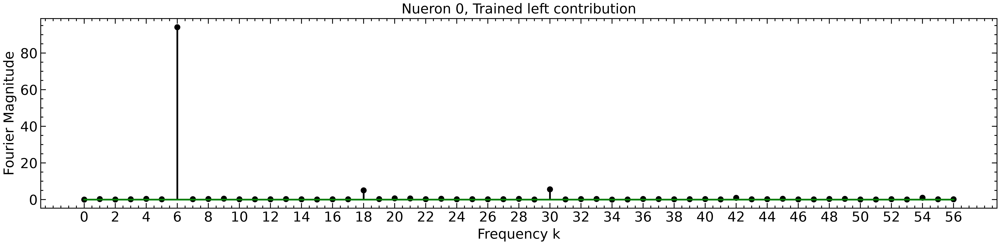

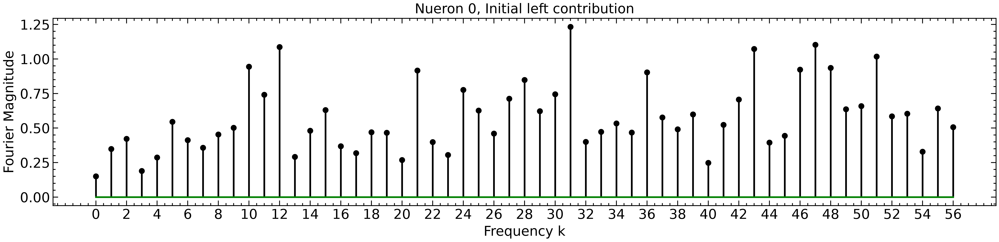

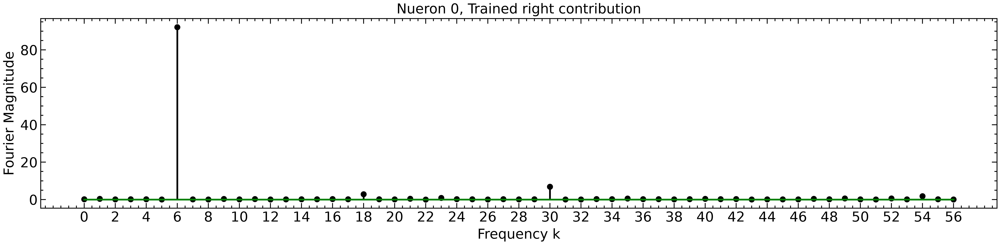

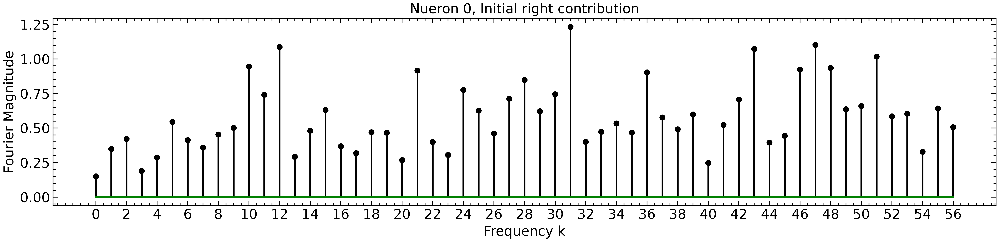

In [180]:
neuron = 0 
left_contrib_initial = initial_model.compute_hidden_preactivations(side="left", neuron=neuron)
left_contrib_trained = trained_model.compute_hidden_preactivations(side="left", neuron=neuron)


right_contrib_initial = initial_model.compute_hidden_preactivations(side="right", neuron=neuron)
right_contrib_trained = trained_model.compute_hidden_preactivations(side="right", neuron=neuron)

model_contribs = {
    "Trained left" : left_contrib_trained, 
    "Initial left" : left_contrib_initial, 

    "Trained right" : right_contrib_trained,
    "Initial right"  : left_contrib_initial

}

print(f"{left_contrib_initial.shape = }")
print(f"{left_contrib_trained.shape = }")
print(f"{right_contrib_initial.shape = }")
print(f"{right_contrib_trained.shape = }")

for title, left_contrib in model_contribs.items():
    plt.figure(figsize=(20,4))
    coeffs = np.fft.rfft(left_contrib)
    magnitudes = np.abs(coeffs)
    plt.stem(np.arange(57), np.abs(coeffs))
    plt.xlabel("Frequency k")
    plt.ylabel("Fourier Magnitude")
    plt.title(f"Nueron {neuron}, {title} contribution")
    plt.xticks(np.arange(0, 57, 2))
    plt.show()


Both left and right contributions have dominant frequency $k = 6$. Can we reconstruct the neuron activations?

Our wave should be:

$$\frac{1}{113} (c_k e^{2\pi i k x / 113}) = c_6 e^{2 \pi i 6x / 113}$$



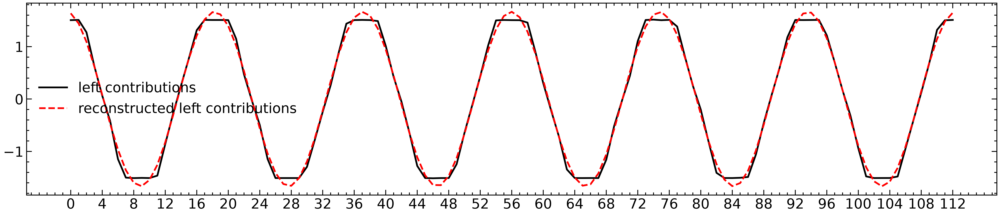

In [181]:
k = 6

c_6_left = np.fft.rfft(left_contrib_trained)[k]


x = np.arange(113)
y_left = (2 / 113) * np.real((c_6_left * np.exp(2 * np.pi * 1j * x * k/ 113)))

plt.figure(figsize=(20,4))
plt.plot(left_contrib_trained, label='left contributions')
plt.plot(x,y_left, label='reconstructed left contributions')
plt.xticks(np.arange(0, 113, 4))
plt.legend()
plt.show()

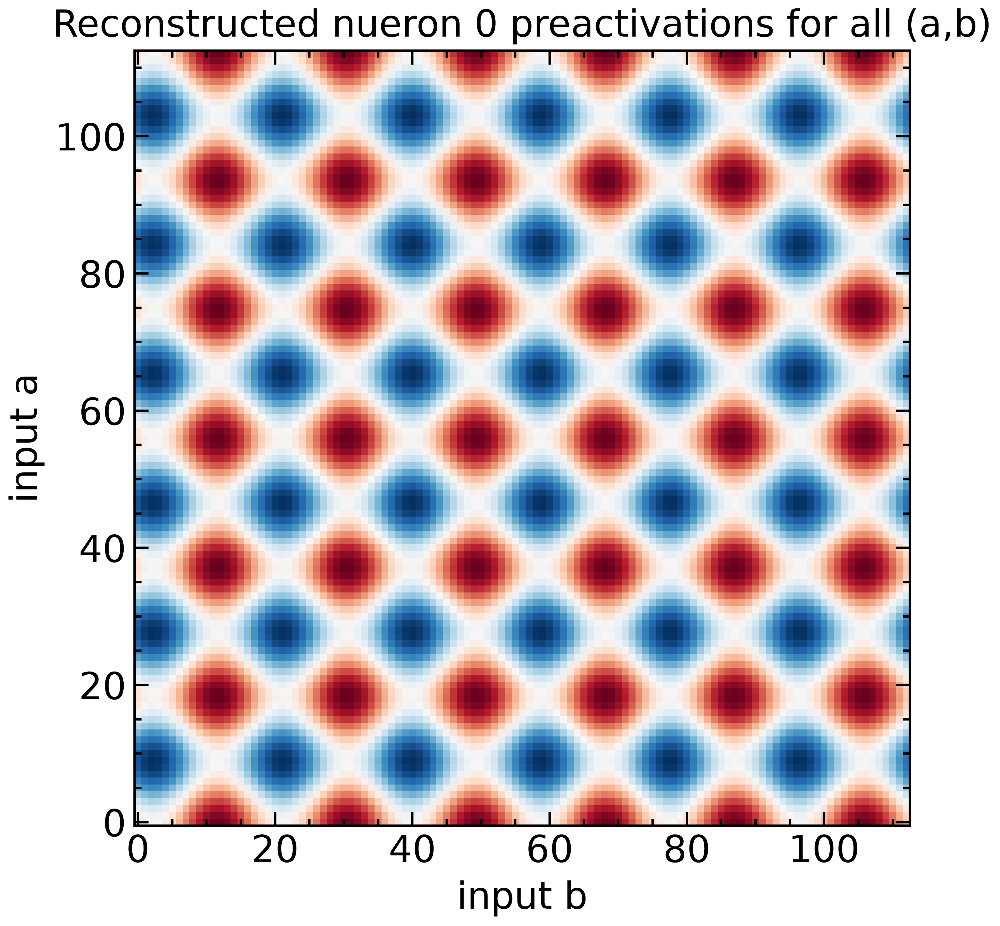




In [182]:
c_6_right = np.fft.rfft(right_contrib_trained)[k]
y_right = (2 / 113) * np.real(c_6_right * np.exp(2j * np.pi * k * x / 113))


grid = y_left[:, None] + y_right[None, :]
plt.imshow(grid, origin="lower", cmap="RdBu_r")
plt.title(f"Reconstructed nueron {neuron} preactivations for all (a,b)")
plt.xlabel("input b")
plt.ylabel("input a")

trained_model.plot_hidden_neuron_values(0)

### What do our embedding matrices look like?
Let us consider where this periodicity has come from. Each $a,b \in G$ is assigned a vector $\mathbf{v}_a, \mathbf{v}_b \in \mathbb{R}^d$. These vectors are learned during training and determine how elements are represented within the network. 

Since we have observed periodicity in the neuron contributions, we investigate whether this periodicity is already present in the learned embedding matrices $E_L$ and $E_R$. We aim to explore how embedding vector coordinates vary as we move through the elements of $G$

We recall, our left embedding matrix is defined as:


$$E_L =
\begin{bmatrix}
| & | & | & & | \\
\mathbf{v}_0 & \mathbf{v}_1 & \mathbf{v}_2 & \cdots & \mathbf{v}_{|G|-1} \\
| & | & | & & |
\end{bmatrix}
=
\begin{bmatrix}
v_{0,0} & v_{1,0} & v_{2,0} & \cdots & v_{|G|-1,0} \\
v_{0,1} & v_{1,1} & v_{2,1} & \cdots & v_{|G|-1,1} \\
\vdots & \vdots & \vdots & \ddots & \vdots \\
v_{0,d-1} & v_{1,d-1} & v_{2,d-1} & \cdots & v_{|G|-1,d-1}
\end{bmatrix}
\in \mathbb{R}^{d \times |G|}$$

The columns of our matrix are the embeddings of our group elements. Consider the $j-th$ row which records the $jth$ coordinate of every embedding vector as we vary the group element $a$
$$
\begin{bmatrix} v_{0,j} & v_{1, j} & v_{2, j} & \cdots & v_{|G|=1, j}\end{bmatrix}
$$ 

For reference, let us consider the untrained model







In [183]:
coordinate = 1
k = 1

E_L_untrained = initial_model.state_dict()['E_L']
E_L_untrained = E_L_untrained.numpy()

coord_row = E_L_untrained[coordinate, :]

plt.figure(figsize=(30,2))
plt.plot(coord_row)
plt.title(f"Coordinate {coordinate}  of Left Embedding as we vary group element a")
plt.xlabel("a")
plt.xticks(np.arange(0, coord_row.shape[0], 5))
plt.show()

coeffs = np.fft.rfft(coord_row)
magnitudes = np.abs(coeffs)
top_k = np.argsort(magnitudes)[::-1][:k]

plt.figure(figsize=(30,2))
plt.stem(np.arange(coord_row.shape[0]/2), magnitudes)
plt.title(f"Frequencies present in Coordiante {coordinate} as we vary group element a")
plt.xlabel("K")
plt.ylabel("Magnitudes")
plt.xticks(np.arange(0, coord_row.shape[0]/2, 1))
plt.show()

Comparing to the trained model, we find it has learned a sparse set of frequencies







In [184]:
coordinate = 1
k = 1


coord_row = E_L[coordinate, :]

plt.figure(figsize=(30,2))
plt.plot(coord_row)
plt.title(f"Coordinate {coordinate}  of Left Embedding as we vary group element a")
plt.xlabel("a")
plt.xticks(np.arange(0, coord_row.shape[0], 5))
plt.show()

coeffs = np.fft.rfft(coord_row)
magnitudes = np.abs(coeffs)
top_k = np.argsort(magnitudes)[::-1][:k]

plt.figure(figsize=(30,2))
plt.stem(np.arange(coord_row.shape[0]/2), magnitudes)
plt.title(f"Frequencies present in Coordiante {coordinate} as we vary group element a")
plt.xlabel("K")
plt.ylabel("Magnitudes")
plt.xticks(np.arange(0, coord_row.shape[0]/2, 1))
plt.show()

We now calculate the fourier frequncies for each row in our matirx and take the $L^2$ norm across the rows at each frequency 




In [191]:
nrows = E_L_untrained.shape[0]
n_freqs = E_L_untrained.shape[1] // 2 + 1

matrix_magnitudes = np.zeros((nrows, n_freqs))
for row_idx in range(nrows):
    curr_row = E_L_untrained[row_idx, :]

    coeffs = np.fft.rfft(curr_row)
    curr_row_magnitudes = np.abs(coeffs)
    
    matrix_magnitudes[row_idx, :] = curr_row_magnitudes


frequency_magnitudes = np.linalg.norm(matrix_magnitudes, axis=0)


plt.figure(figsize=(30,2))
plt.stem(np.arange(frequency_magnitudes.shape[0]), frequency_magnitudes)
plt.xticks(np.arange(n_freqs))
plt.title("Fourier Spectrum of the Left Embedding Matrix")
plt.xlabel("K")
plt.show()




In [192]:
nrows = E_L.shape[0]
n_freqs = E_L.shape[1] // 2 + 1

matrix_magnitudes = np.zeros((nrows, n_freqs))
for row_idx in range(nrows):
    curr_row = E_L[row_idx, :]

    coeffs = np.fft.rfft(curr_row)
    curr_row_magnitudes = np.abs(coeffs)
    
    matrix_magnitudes[row_idx, :] = curr_row_magnitudes


frequency_magnitudes = np.linalg.norm(matrix_magnitudes, axis=0)


plt.figure(figsize=(30,2))
plt.stem(np.arange(frequency_magnitudes.shape[0]), frequency_magnitudes)
plt.xticks(np.arange(n_freqs))
plt.title("Fourier Spectrum of the Left Embedding Matrix")
plt.xlabel("K")
plt.show()

We find our embedding matrix is sparse in fourier frequencies:
$$K = \{6,22,23,30,40,54\}$$

In [202]:
top_7 = frequency_magnitudes.argsort()[::-1][:7]

print(f"Top 7 frequencies in the left embedding matrix  : {top_7}")

Top 7 frequencies in the left embedding matrix  : [22 49 23 40 30  6 54]
